<a href="https://colab.research.google.com/github/taissa-arruda/prog_estat/blob/main/Resolu%C3%A7%C3%A3o_labs/Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exercício 1**

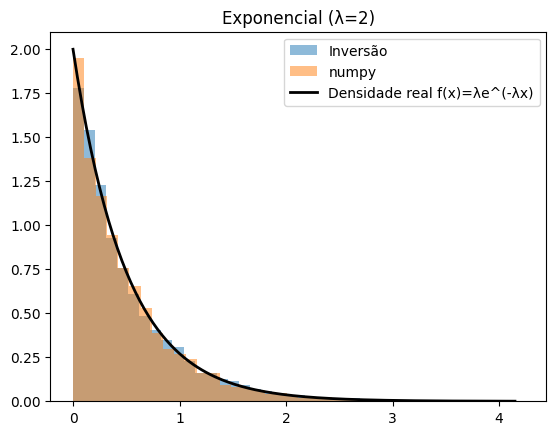

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def exponencial_inversao(lam):
    u = np.random.uniform()
    return -np.log(1 - u) / lam

M = 5000
lam = 2

amostra_inversao = np.array([exponencial_inversao(lam) for _ in range(M)])
amostra_numpy = np.random.exponential(scale=1/lam, size=M)

x = np.linspace(0, amostra_inversao.max(), 200)
densidade_real = lam * np.exp(-lam * x)

plt.hist(amostra_inversao, bins=40, density=True, alpha=0.5, label='Inversão')
plt.hist(amostra_numpy, bins=40, density=True, alpha=0.5, label='numpy')
plt.plot(x, densidade_real, 'k-', linewidth=2, label='Densidade real f(x)=λe^(-λx)')
plt.legend()
plt.title(f'Exponencial (λ={lam})')
plt.show()

**Exercício 2**

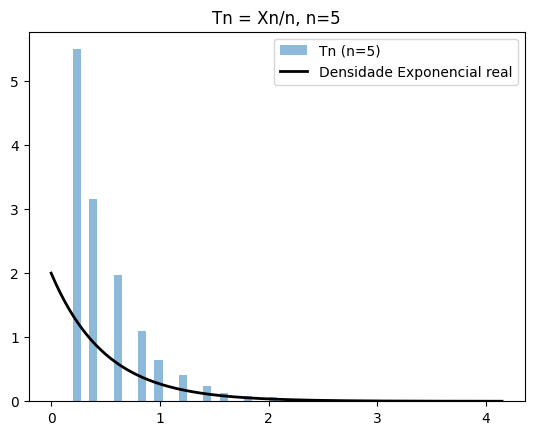

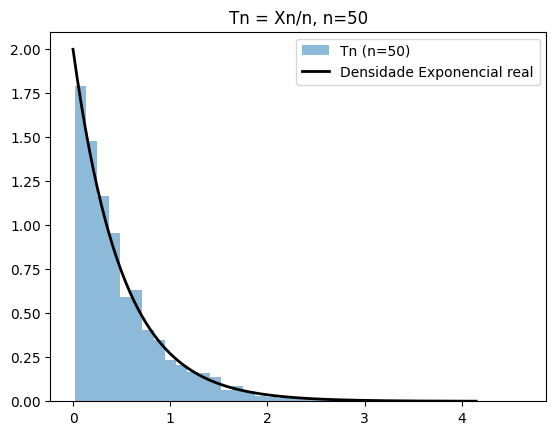

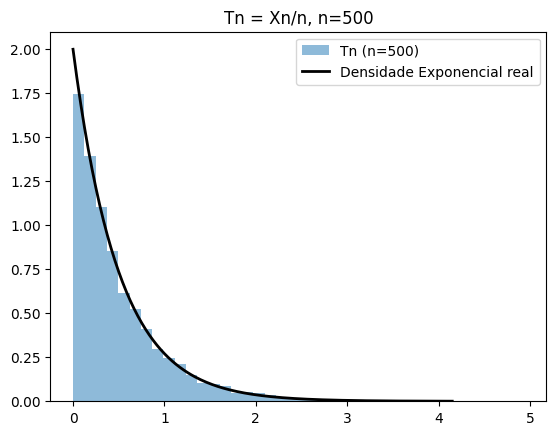

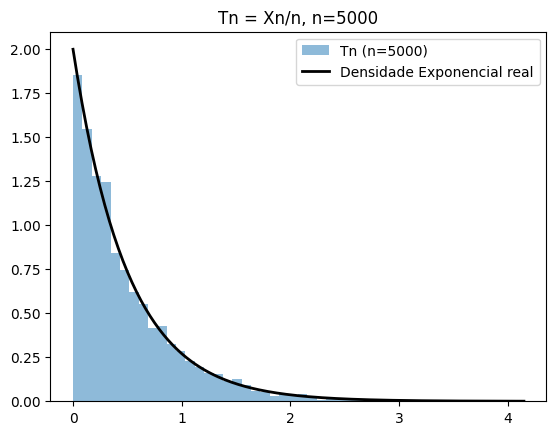

In [3]:
def geometrica_inversao(p):
    u = np.random.uniform()
    return np.ceil(np.log(1 - u) / np.log(1 - p))

valores_n = [5, 50, 500, 5000]

for n in valores_n:
    p = lam / n
    Xn = np.array([geometrica_inversao(p) for _ in range(M)])
    Tn = Xn / n

    plt.hist(Tn, bins=40, density=True, alpha=0.5, label=f'Tn (n={n})')
    plt.plot(x, densidade_real, 'k-', linewidth=2, label='Densidade Exponencial real')
    plt.legend()
    plt.title(f'Tn = Xn/n, n={n}')
    plt.show()

**Exercício 3**

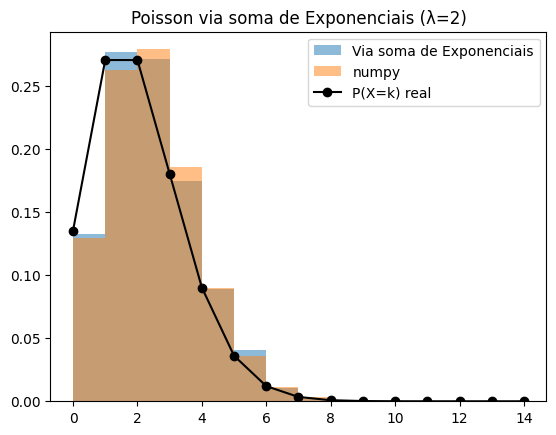

In [5]:
def conta_poisson(lam):
    soma = 0
    contagem = 0
    while soma <= 1:
        soma += exponencial_inversao(lam)
        contagem += 1
    return contagem - 1  # não conta a exponencial que fez passar de 1

amostra_poisson_simulada = np.array([conta_poisson(lam) for _ in range(M)])
amostra_poisson_numpy = np.random.poisson(lam, M)

# Probabilidade teórica da Poisson, calculada passo a passo (sem fatorial)
k = np.arange(0, 15)
pmf_real = []
p = np.exp(-lam)   # P(X=0)
for i in k:
    pmf_real.append(p)
    p = p * lam / (i + 1)   # calcula a próxima probabilidade a partir da anterior

plt.hist(amostra_poisson_simulada, bins=range(15), density=True, alpha=0.5, label='Via soma de Exponenciais')
plt.hist(amostra_poisson_numpy, bins=range(15), density=True, alpha=0.5, label='numpy')
plt.plot(k, pmf_real, 'ko-', label='P(X=k) real')
plt.legend()
plt.title(f'Poisson via soma de Exponenciais (λ={lam})')
plt.show()